In [1]:
import xgboost as xgb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_pinball_loss
from datetime import datetime, timedelta

In [2]:
X_train = np.load('../../output/data_eagles_vezhen/qrf/X_train2.npy')
y_train = np.load('../../output/data_eagles_vezhen/qrf/y_train2.npy')
X_test = np.load('../../output/data_eagles_vezhen/qrf/X_test2.npy')
y_test = np.load('../../output/data_eagles_vezhen/qrf/y_test2.npy')
X_val = np.load('../../output/data_eagles_vezhen/qrf/X_val2.npy')
y_val = np.load('../../output/data_eagles_vezhen/qrf/y_val2.npy')

SLIDINGW_STEPS = 5
N_OUT_FEATS = y_train.shape[-1]
N_INP_FEATS = X_train.shape[-1]

y_train = y_train.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_train = X_train.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))
y_val = y_val.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_val = X_val.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))
y_test = y_test.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_test = X_test.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))

In [3]:
vezhen_y = np.load('../../output/data_eagles_vezhen/qrf/vezhen_y3.npy', allow_pickle=True)\
    .reshape((-1, 5*3))
vezhen_x = np.load('../../output/data_eagles_vezhen/qrf/vezhen_x3.npy', allow_pickle=True)\
    .reshape((-1, 5*20))
eagles_y = np.load('../../output/data_eagles_vezhen/qrf/eagles_y3.npy', allow_pickle=True)\
    .reshape((-1, 5*3))
eagles_x = np.load('../../output/data_eagles_vezhen/qrf/eagles_x3.npy', allow_pickle=True)\
    .reshape((-1, 5*20))

## Validation on anomalous cases

In [4]:
FEAT_NAMES = ['Delta COG', 'Delta DIF', 'DIF']

In [5]:
def test_xgboost_feature(feat:int, feat_name:str, hyper: dict):
    in_pi_mask = None
    eagles_low = None
    eagles_high = None
    vezhen_low = None
    vezhen_high = None

    for t in range(5):

        y_train_tmp = y_train\
            .reshape((-1, 5, 3))\
            [:, t, feat]
        y_val_tmp = y_val\
            .reshape((-1, 5, 3))\
            [:, t, feat]

        model_low = xgb.XGBRegressor(
            objective='reg:quantileerror',
            quantile_alpha=0.025,
            device='gpu',
            **hyper
        )

        model_high = xgb.XGBRegressor(
            objective='reg:quantileerror',
            quantile_alpha=0.975,
            device='gpu',
            **hyper
        )

        feat = 0
        model_low.fit(X_train, y_train_tmp)
        model_high.fit(X_train, y_train_tmp)

        eagles_low_slice = model_low.predict(eagles_x)
        eagles_high_slice = model_high.predict(eagles_x)
        vezhen_low_slice = model_low.predict(vezhen_x)
        vezhen_high_slice = model_high.predict(vezhen_x)

        y_low = model_low.predict(X_val)
        y_high = model_high.predict(X_val)

        val_mmsis = np.load('../../output/data_eagles_vezhen/qrf/val-mmsis2.npy', allow_pickle=True)
        val_days = np.load('../../output/data_eagles_vezhen/qrf/val-days2.npy', allow_pickle=True)

        in_pi_mask_slice = (y_val_tmp > y_low) & (y_val_tmp < y_high)
        if t == 0:
            in_pi_mask = in_pi_mask_slice.reshape((-1,1))
            eagles_low = eagles_low_slice.reshape((-1,1))
            eagles_high = eagles_high_slice.reshape((-1,1))
            vezhen_low = vezhen_low_slice.reshape((-1,1))
            vezhen_high = vezhen_high_slice.reshape((-1,1))

        else:

            in_pi_mask = np.concatenate([
                in_pi_mask,
                in_pi_mask_slice.reshape((-1,1))
            ], axis=1)

            eagles_low = np.concatenate([
                eagles_low,
                eagles_low_slice.reshape((-1,1))
            ], axis=1)
            eagles_high = np.concatenate([
                eagles_high,
                eagles_high_slice.reshape((-1,1))
            ], axis=1)

            vezhen_low = np.concatenate([
                vezhen_low,
                vezhen_low_slice.reshape((-1,1))
            ], axis=1)
            vezhen_high = np.concatenate([
                vezhen_high,
                vezhen_high_slice.reshape((-1,1))
            ], axis=1)

    group_results = {}
    for ix, (mmsi, day) in enumerate(zip(val_mmsis, val_days)):
    
        if (mmsi, day) not in group_results:
            group_results[(mmsi, day)] = [ in_pi_mask[ix, :] ]
        else:
            group_results[(mmsi, day)].append( in_pi_mask[ix, :] )

    df = []

    for (mmsi, day), pi_masks in group_results.items():
        means = np.mean(pi_masks)
        df.append({
            'mmsi': mmsi,
            'day': day,
            'delta_cog': means
        })

    df = pd.DataFrame(df)
    print(feat_name, ':', np.quantile( df['delta_cog'], 0.05 ) )

    eagles_y_tmp = eagles_y.reshape((-1, 5, 3))[:, :, feat]
    print('EAGLE S', feat_name,
            np.mean( (eagles_y_tmp < eagles_high) & (eagles_y_tmp > eagles_low) ) )

    vezhen_y_tmp = vezhen_y.reshape((-1, 5, 3))[:, :, feat]
    print('VEZHEN', feat_name,
            np.mean( (vezhen_y_tmp < vezhen_high) & (vezhen_y_tmp > vezhen_low) ) )


    return (
        eagles_y_tmp,
        eagles_low,
        eagles_high,
        vezhen_y_tmp,
        vezhen_low,
        vezhen_high
    )

In [6]:
best_hyper = {
    'n_estimators': 128,
    'max_depth': 4,
    'eta': 0.05,
    'subsample': 0.8,
}

(
    eagles_true_delta_cog,
    eagles_low_delta_cog,
    eagles_high_delta_cog,
    vezhen_true_delta_cog,
    vezhen_low_delta_cog,
    vezhen_high_delta_cog
) = test_xgboost_feature(0, feat_name='Delta COG', hyper=best_hyper)

/home/lukas/straipsnis/qrf-venv/lib/python3.12/site-packages/xgboost/core.py:553: UserWarning: [19:38:15] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Delta COG : 0.8867307692307692
EAGLE S Delta COG 0.8827586206896552
VEZHEN Delta COG 0.9445086705202312


In [7]:
best_hyper = {
    'n_estimators': 128,
    'max_depth': 4,
    'eta': 0.05,
    'subsample': 0.8,
}

(
    eagles_true_delta_dif,
    eagles_low_delta_dif,
    eagles_high_delta_dif,
    vezhen_true_delta_dif,
    vezhen_low_delta_dif,
    vezhen_high_delta_dif
) = test_xgboost_feature(1, feat_name='Delta DIF', hyper=best_hyper)

Delta DIF : 0.8856525423728814
EAGLE S Delta DIF 0.8482758620689655
VEZHEN Delta DIF 0.8953757225433526


In [8]:
best_hyper = {
    'n_estimators': 128,
    'max_depth': 4,
    'eta': 0.05,
    'subsample': 1.0,
}

(
    eagles_true_dif,
    eagles_low_dif,
    eagles_high_dif,
    vezhen_true_dif,
    vezhen_low_dif,
    vezhen_high_dif
) = test_xgboost_feature(2, feat_name='DIF', hyper=best_hyper)

DIF : 0.8775641025641026
EAGLE S DIF 0.8586206896551725
VEZHEN DIF 0.884393063583815


## Illustration

In [9]:
timestamps_eagles = pd.date_range(
    start=datetime(2024, 12, 25, 10, 45),
    end=datetime(2024, 12, 25, 16, 40),
    periods=eagles_x.shape[0]
)
timestamps_eagles.shape

(58,)

In [10]:
def plot_pi(
    ship_name:str,
    feat_name:str,
    y_true:np.array,
    y_low:np.array,
    y_high: np.array,
    plot_ticks:list,
    plot_labels:list,
    ax:plt.Axes,
    include_xtitle:bool=False,
    legend_loc:str=None
):

    anomalies_x = []
    anomalies_y = []

    for i in range(y_true.shape[0]):

        if y_true[i] < y_low[i]:
            anomalies_x.append( timestamps_eagles[i] )
            anomalies_y.append( y_true[i] )

        elif y_true[i] > y_high[i]:
            anomalies_x.append( timestamps_eagles[i] )
            anomalies_y.append( y_true[i] )

    ax.plot(timestamps_eagles, y_true, label = "Target value", color='black', alpha=0.6)
    ax.plot(timestamps_eagles, y_low, color='#185288', linestyle='--')
    ax.plot(timestamps_eagles, y_high, color="#185288", linestyle='--')

    ax.set_xticks(
        ticks=plot_ticks,
        labels=plot_labels
    )
    ax.tick_params(axis='both', which='both', labelsize=13)

    if include_xtitle:
        ax.set_xlabel('Timestamp (UTC)', size=18)
    ax.set_ylabel(rf'{feat_name}', size=18)
    ax.set_title(rf'{ship_name} {feat_name} PI', size=20)

    ax.fill_between(x=timestamps_eagles, y1=y_low, y2=y_high, alpha=0.3, label='Prediction interval')
    ax.scatter(anomalies_x, anomalies_y, color='red', s=20, zorder=5, label='Anomalies')

    if legend_loc:
        ax.legend(fontsize=13, framealpha=0.5, loc=legend_loc)
    else:
        ax.legend(fontsize=13, framealpha=0.5, loc='upper right')

In [11]:
plt.style.use('bmh')
plt.rcParams['axes.facecolor'] = 'white'

/tmp/ipykernel_4869/571959778.py:16: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


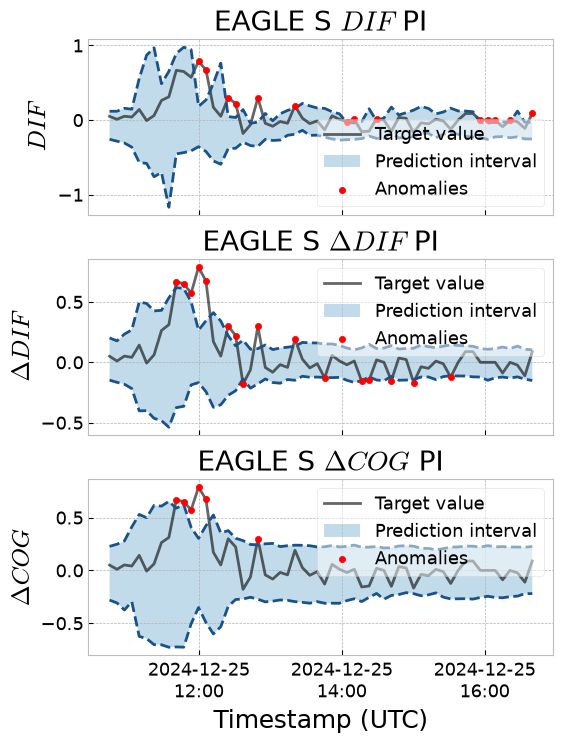

In [12]:
fig, axs=plt.subplots(nrows=3, figsize=(6,8), gridspec_kw={'hspace': 0.25}, sharex=True)

ticks = [
    datetime(2024, 12, 25, 12, 0) + timedelta(hours=1)*i
    for i in range(0,6,2)
]
labels = [
    tick.strftime('%Y-%m-%d\n%H:%M')
    for tick in ticks
]

plot_pi('EAGLE S', '$DIF$', eagles_true_dif[:, 0], eagles_low_dif[:, 0], eagles_high_dif[:, 0], ticks, labels, ax=axs[0], legend_loc='lower right')
plot_pi('EAGLE S', r'$\Delta DIF$', eagles_true_delta_dif[:, 0], eagles_low_delta_dif[:, 0], eagles_high_delta_dif[:, 0], ticks, labels, ax=axs[1])
plot_pi('EAGLE S', r'$\Delta COG$', eagles_true_delta_cog[:, 0], eagles_low_delta_cog[:, 0], eagles_high_delta_cog[:, 0], ticks, labels, ax=axs[2], include_xtitle=True)

plt.tight_layout()
plt.savefig('eagles-results.png', dpi=750)


## False positive calculation

## SHAP

In [13]:
import shap

In [14]:
hyper = {
    'n_estimators': 128,
    'max_depth': 4,
    'eta': 0.05,
    'subsample': 1.0,
}
feat=2 #dif

model_low = xgb.XGBRegressor(
    objective='reg:quantileerror',
    quantile_alpha=0.025,
    device='gpu',
    **hyper
)

model_high = xgb.XGBRegressor(
    objective='reg:quantileerror',
    quantile_alpha=0.975,
    device='gpu',
    **hyper
)

y_train_tmp = y_train\
    .reshape((-1,5,3))\
    [:, 0, feat]

model_low.fit(X_train, y_train_tmp)
model_high.fit(X_train, y_train_tmp)

eagles_low_slice = model_low.predict(eagles_x)
eagles_high_slice = model_high.predict(eagles_x)

In [15]:
features = [
    'SPEED', 'COURSE', 'currentSpeed', 'gust', 'swellHeight',
    'waveHeight', 'windSpeed', 'dif', 'COURSE-dif', 'delta_dif',
    'COURSE_vec_x', 'COURSE_vec_y', 'currentDirection_vec_x',
    'currentDirection_vec_y', 'swellDirection_vec_x',
    'swellDirection_vec_y', 'waveDirection_vec_x', 'waveDirection_vec_y',
    'windDirection_vec_x', 'windDirection_vec_y'
]
feature_names = [
    'SOG', 'COG', 'CurrentSpeed', 'Gust', 'SwellHeight',
    'WaveHeight', 'WindSpeed', 'DIF', r'\Delta COG',
    r'\Delta DIF', 'COG_x', 'COG_y', 'CurrentDirection_x',
    'CurrentDirection_y', 'SwellDirection_x', 'SwellDirection_y',
    'WaveDirection_x', 'WaveDirection_y', ' WindDirection_x', 'WindDirection_y'
]

feature_names = [
    rf'${col}(t-{t})$' if t != 0 else f'${col}(t)$'
    for t in range(0,25,5)
    for col in feature_names
]

explainer_high = shap.TreeExplainer(model_high, feature_names=feature_names)
explainer_low = shap.TreeExplainer(model_low, feature_names=feature_names)

shap_high = explainer_high(eagles_x)
shap_low = explainer_low(eagles_x)

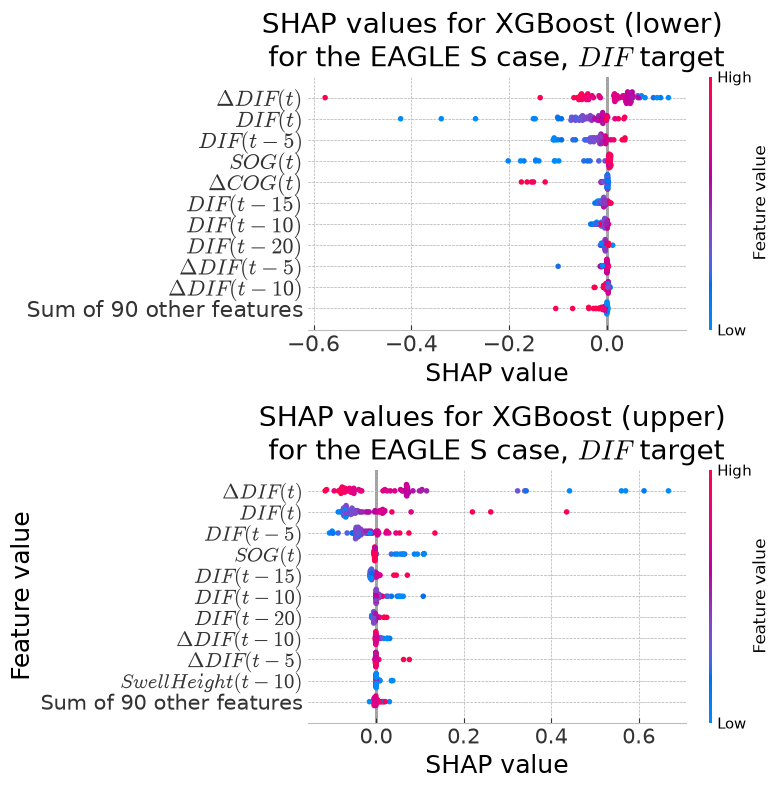

In [16]:
fig, axs = plt.subplots(2, 1)
plt.sca(axs[0])
shap.plots.beeswarm(shap_low, show=False, plot_size=(8,8), max_display=11)

axs[0].set_title('SHAP values for XGBoost (lower) \nfor the EAGLE S case, $DIF$ target', size=20)
axs[0].tick_params(axis='both', labelsize=16)
axs[0].set_xlabel('SHAP value', size=18)

# https://github.com/shap/shap/issues/594#issuecomment-1206481300
cbar = plt.gcf().axes[1]
cbar.tick_params(labelsize=15)
cbar.set_ylabel("Feature value", fontsize=18)

plt.sca(axs[1])
shap.plots.beeswarm(shap_high, show=False, plot_size=(8,8), max_display=11)

axs[1].set_title('SHAP values for XGBoost (upper) \nfor the EAGLE S case, $DIF$ target', size=20)
axs[1].tick_params(axis='both', labelsize=16)
axs[1].set_xlabel('SHAP value', size=18)

# https://github.com/shap/shap/issues/594#issuecomment-1206481300
cbar = plt.gcf().axes[1]
cbar.tick_params(labelsize=15)
cbar.set_ylabel("Feature value", fontsize=18)

plt.tight_layout()
plt.savefig('shap-values-eagles.png', dpi=750)
plt.show()

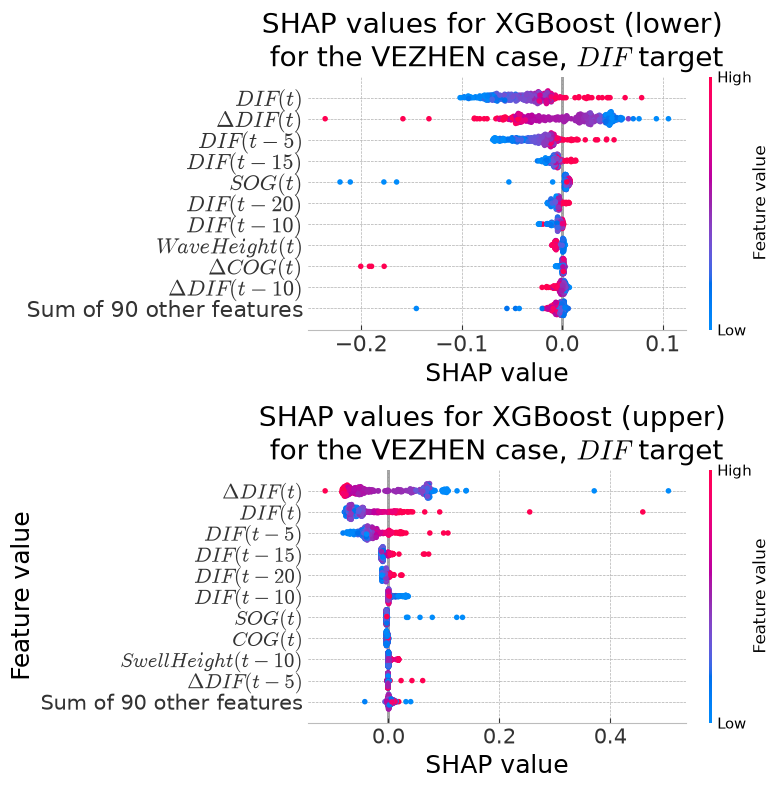

In [17]:
shap_high = explainer_high(vezhen_x)
shap_low = explainer_low(vezhen_x)

fig, axs = plt.subplots(2, 1)
plt.sca(axs[0])
shap.plots.beeswarm(shap_low, show=False, plot_size=(8,8), max_display=11)

axs[0].set_title('SHAP values for XGBoost (lower) \nfor the VEZHEN case, $DIF$ target', size=20)
axs[0].tick_params(axis='both', labelsize=16)
axs[0].set_xlabel('SHAP value', size=18)

# https://github.com/shap/shap/issues/594#issuecomment-1206481300
cbar = plt.gcf().axes[1]
cbar.tick_params(labelsize=15)
cbar.set_ylabel("Feature value", fontsize=18)

plt.sca(axs[1])
shap.plots.beeswarm(shap_high, show=False, plot_size=(8,8), max_display=11)

axs[1].set_title('SHAP values for XGBoost (upper) \nfor the VEZHEN case, $DIF$ target', size=20)
axs[1].tick_params(axis='both', labelsize=16)
axs[1].set_xlabel('SHAP value', size=18)

# https://github.com/shap/shap/issues/594#issuecomment-1206481300
cbar = plt.gcf().axes[1]
cbar.tick_params(labelsize=15)
cbar.set_ylabel("Feature value", fontsize=18)

plt.tight_layout()
plt.savefig('shap-values-vezhen.png', dpi=750)
plt.show()

In [29]:
mask_shap_low = shap_low.values[:, 0] < -0.15
shap_low.data[mask_shap_low, 0]

array([-0.98387097, -0.98387097, -0.91935484, -0.82258065])

In [31]:
shap_low.values[mask_shap_low, 0]

array([-0.17744324, -0.22110428, -0.21090107, -0.16477595], dtype=float32)

In [32]:
shap_low.base_values[0]

np.float32(-0.17446445)

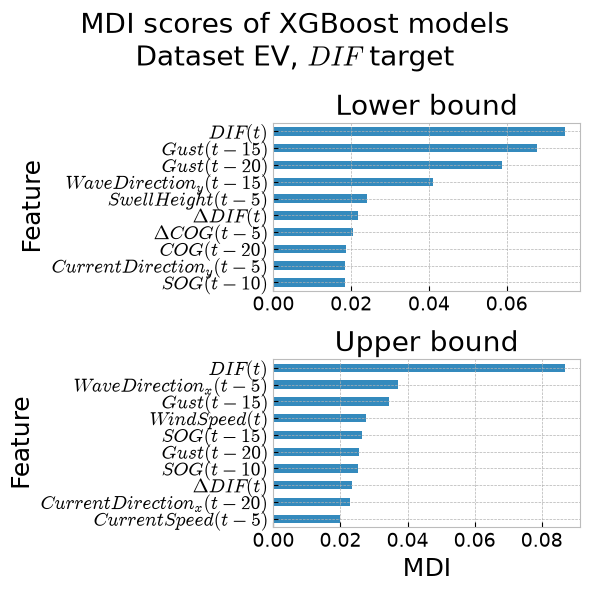

In [18]:
fig, axs = plt.subplots(nrows=2, figsize=(6,6))
fig.suptitle('MDI scores of XGBoost models\nDataset EV, $DIF$ target', size=20)

df_imp = pd.DataFrame({
    'Feature': feature_names,
    'Feature importance': model_low.feature_importances_
})
df_imp\
    .set_index(keys='Feature')\
    .sort_values(by='Feature importance', ascending=True)\
    .tail(10)\
    .plot.barh(ax=axs[0])

# Source - https://stackoverflow.com/a/26845924
# Posted by naitsirhc, modified by community. See post 'Timeline' for change history
# Retrieved 2026-09-23, License - CC BY-SA 4.0
axs[0].get_legend().remove()
axs[0].tick_params(axis='both', labelsize=14)
axs[0].set_ylabel('Feature', size=18)
axs[0].set_title('Lower bound', size=20)

df_imp = pd.DataFrame({
    'Feature': feature_names,
    'Feature importance': model_high.feature_importances_
})
df_imp\
    .set_index(keys='Feature')\
    .sort_values(by='Feature importance', ascending=True)\
    .tail(10)\
    .plot.barh(ax=axs[1])

# Source - https://stackoverflow.com/a/26845924
# Posted by naitsirhc, modified by community. See post 'Timeline' for change history
# Retrieved 2026-09-23, License - CC BY-SA 4.0
axs[1].get_legend().remove()
axs[1].tick_params(axis='both', labelsize=14)
axs[1].set_ylabel('Feature', size=18)
axs[1].set_xlabel('MDI', size=18)
axs[1].set_title('Upper bound', size=20)

plt.tight_layout()
plt.savefig('mdi-scores-xgboost-ev.png', dpi=750)

## False positives

In [22]:
test_mmsis = np.load('../../output/data_eagles_vezhen/qrf/test-mmsis2.npy', allow_pickle=True)
test_days = np.load('../../output/data_eagles_vezhen/qrf/test-days2.npy', allow_pickle=True)


def calc_false_positve(var_num: int, thresh: float):
    
    model_low = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=0.025,
        device='gpu',
        **best_hyper
    )
    
    model_high = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=0.975,
        device='gpu',
        **best_hyper
    )
    
    model_low.fit(X_train, y_train[:, var_num])
    model_high.fit(X_train, y_train[:, var_num])
    y_low = model_low.predict(X_test)
    y_high = model_high.predict(X_test)
    
    in_pi_mask = (y_test[:, var_num] > y_low) & (y_test[:, var_num] < y_high)
    
    group_results = {}
    for ix, (mmsi, day) in enumerate(zip(test_mmsis, test_days)):
        
        if (mmsi, day) not in group_results:
            group_results[(mmsi, day)] = [ in_pi_mask[ix] ]
        else:
            group_results[(mmsi, day)].append( in_pi_mask[ix] )
    
    df = []
    
    for (mmsi, day), pi_masks in group_results.items():
        mean = np.mean(pi_masks)
        df.append({
            'mmsi': mmsi,
            'day': day,
            'coverage': mean
        })
    
    df = pd.DataFrame(df)
    return np.mean(df['coverage'] < thresh)

In [23]:
# taken from the top
thresholds = [
    0.8867307692307692,
    0.8856525423728814,
    0.8775641025641026
]

for i in range(3):
    print( i, calc_false_positve(i, thresholds[i]) )

0 0.12658227848101267
1 0.11392405063291139
2 0.05063291139240506


In [34]:
# from https://github.com/amaa11/NMR
X_train_df = pd.DataFrame(X_train, columns=feature_names)
X_test_df = pd.DataFrame(eagles_x, columns=feature_names)
y_train_dif = y_train[:, 2]

dicts = dict()
m = 0
MPM_list = []

while X_train_df.shape[1] != 1:

    MPM = 0
    NF = X_train_df.shape[1]
    for j in range(1, NF, 2):
        summ = NF-j
        MPM = MPM+summ
    MPM = MPM*2
    MPM_list.append(MPM)
    #print('MPM :', MPM)
    
    ITER_NUMBER = X_train_df.shape[1]                          ## number of features in each iteration
    model_low = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=0.025,
        device='gpu',
        **best_hyper
    )
    model_low.fit(X_train_df, y_train_dif)                      ## fit the data to the model
    ypred_test = model_low.predict(X_test_df)                             ## predict test data
    
    # fit shap
    explainer = shap.TreeExplainer(model_low)

    # apply shap to test data
    shap_values = explainer.shap_values(X_test_df)
    
    # the follwoing steps to represents the SHAP outcome (informative predictors) as datafram
    vals= np.abs(shap_values).mean(0)
    feature_importance = pd.DataFrame(list(zip(X_train_df.columns,vals)),columns=['Features','feature_importance_vals'])
    feature_importance.sort_values(by=['feature_importance_vals'],ascending=False,inplace=True)
    feature_importance.reset_index(inplace=True, drop=True)
    feature_importance.index = np.arange(1, len(feature_importance) + 1)
    #print(feature_importance)
    FEATURES = feature_importance[['Features']]
    #print(FEATURES)
    for i in range(FEATURES.shape[0]):
        #print(FEATURES.iloc[i]['Features'], end = " ")
        #print(FEATURES.iloc[i].name, end = " ")
        #for key in dicts:
        if FEATURES.iloc[i]['Features'] in dicts:
            dicts[FEATURES.iloc[i]['Features']].append(FEATURES.iloc[i].name + m)
        else:
            dicts[FEATURES.iloc[i]['Features']] = [FEATURES.iloc[i].name + m]
    
    m = m+1
    # identify the most informative predictor
    Top_feature = feature_importance.iloc[0]['Features']
    
    # remove the most informative predictor from train and test data
    X_train_df.drop([Top_feature], axis=1, inplace=True)
    X_train_df.reset_index(inplace=True, drop=True)
    X_test_df.drop([Top_feature], axis=1, inplace=True)
    X_test_df.reset_index(inplace=True, drop=True)

MPM_list.pop(0)

lenOfLists=len(dicts)
#function to add item at index=len ... append item
def add_item_to_dict(my_dict, key, value):
    my_dict[len(my_dict)] = [key,value]

    
sorted_dict = {}

for index in range(1,lenOfLists):
    for key, value in dicts.items():
        if len(value)==index:
            add_item_to_dict(sorted_dict,key,value)

#calculate sum of changes
sumOfChanges={}
#first is zero
add_item_to_dict(sumOfChanges,sorted_dict[0][0],0)

for index in range(1,lenOfLists-1):  
    key=sorted_dict[index][0]
    soc=0
    for t in range(index,lenOfLists):        
        soc+=abs(sorted_dict[t][1][index]-sorted_dict[t][1][index-1])
        #print(sorted_dict[t][1][index],sorted_dict[t][1][index-1],(sorted_dict[t][1][index]-sorted_dict[t][1][index-1]))
    add_item_to_dict(sumOfChanges,key,soc)
    #print(soc,'----') 
#last is same to last -1
add_item_to_dict(sumOfChanges,sorted_dict[lenOfLists-1][0],sumOfChanges[lenOfLists-2][1])
#print(sorted_dict)
#print(sumOfChanges)
sumOfChanges.popitem()
first_key = next(iter(sumOfChanges))
del sumOfChanges[first_key]
rates = []
ite=0
for key, value in sumOfChanges.items():    
    rates.append(value[1]/MPM_list[ite])
    ite=ite+1
#print(rates)
print("NMR value : ", round(np.mean(rates), 3))

NMR value :  0.382


In [35]:
# from https://github.com/amaa11/NMR
X_train_df = pd.DataFrame(X_train, columns=feature_names)
X_test_df = pd.DataFrame(eagles_x, columns=feature_names)
y_train_dif = y_train[:, 2]

dicts = dict()
m = 0
MPM_list = []

while X_train_df.shape[1] != 1:

    MPM = 0
    NF = X_train_df.shape[1]
    for j in range(1, NF, 2):
        summ = NF-j
        MPM = MPM+summ
    MPM = MPM*2
    MPM_list.append(MPM)
    #print('MPM :', MPM)
    
    ITER_NUMBER = X_train_df.shape[1]                          ## number of features in each iteration
    model_high = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=0.975,
        device='gpu',
        **best_hyper
    )
    model_high.fit(X_train_df, y_train_dif)                      ## fit the data to the model
    ypred_test = model_high.predict (X_test_df)                             ## predict test data
    
    # fit shap
    explainer = shap.TreeExplainer(model_high)

    # apply shap to test data
    shap_values = explainer.shap_values(X_test_df)
    
    # the follwoing steps to represents the SHAP outcome (informative predictors) as datafram
    vals= np.abs(shap_values).mean(0)
    feature_importance = pd.DataFrame(list(zip(X_train_df.columns,vals)),columns=['Features','feature_importance_vals'])
    feature_importance.sort_values(by=['feature_importance_vals'],ascending=False,inplace=True)
    feature_importance.reset_index(inplace=True, drop=True)
    feature_importance.index = np.arange(1, len(feature_importance) + 1)
    #print(feature_importance)
    FEATURES = feature_importance[['Features']]
    #print(FEATURES)
    for i in range(FEATURES.shape[0]):
        #print(FEATURES.iloc[i]['Features'], end = " ")
        #print(FEATURES.iloc[i].name, end = " ")
        #for key in dicts:
        if FEATURES.iloc[i]['Features'] in dicts:
            dicts[FEATURES.iloc[i]['Features']].append(FEATURES.iloc[i].name + m)
        else:
            dicts[FEATURES.iloc[i]['Features']] = [FEATURES.iloc[i].name + m]
    
    m = m+1
    # identify the most informative predictor
    Top_feature = feature_importance.iloc[0]['Features']
    print('Iteration:', ITER_NUMBER, '\tTop feature:', Top_feature)
    
    # remove the most informative predictor from train and test data
    X_train_df.drop([Top_feature], axis=1, inplace=True)
    X_train_df.reset_index(inplace=True, drop=True)
    X_test_df.drop([Top_feature], axis=1, inplace=True)
    X_test_df.reset_index(inplace=True, drop=True)

MPM_list.pop(0)

lenOfLists=len(dicts)
#function to add item at index=len ... append item
def add_item_to_dict(my_dict, key, value):
    my_dict[len(my_dict)] = [key,value]

    
sorted_dict = {}

for index in range(1,lenOfLists):
    for key, value in dicts.items():
        if len(value)==index:
            add_item_to_dict(sorted_dict,key,value)

#calculate sum of changes
sumOfChanges={}
#first is zero
add_item_to_dict(sumOfChanges,sorted_dict[0][0],0)

for index in range(1,lenOfLists-1):  
    key=sorted_dict[index][0]
    soc=0
    for t in range(index,lenOfLists):        
        soc+=abs(sorted_dict[t][1][index]-sorted_dict[t][1][index-1])
        #print(sorted_dict[t][1][index],sorted_dict[t][1][index-1],(sorted_dict[t][1][index]-sorted_dict[t][1][index-1]))
    add_item_to_dict(sumOfChanges,key,soc)
    #print(soc,'----') 
#last is same to last -1
add_item_to_dict(sumOfChanges,sorted_dict[lenOfLists-1][0],sumOfChanges[lenOfLists-2][1])
#print(sorted_dict)
#print(sumOfChanges)
sumOfChanges.popitem()
first_key = next(iter(sumOfChanges))
del sumOfChanges[first_key]
rates = []
ite=0
for key, value in sumOfChanges.items():    
    rates.append(value[1]/MPM_list[ite])
    ite=ite+1
#print(rates)
print("NMR value : ", round(np.mean(rates), 3))

Iteration: 100 	Top feature: $\Delta DIF(t)$
Iteration: 99 	Top feature: $DIF(t)$
Iteration: 98 	Top feature: $DIF(t-5)$
Iteration: 97 	Top feature: $SOG(t)$
Iteration: 96 	Top feature: $SOG(t-5)$
Iteration: 95 	Top feature: $DIF(t-10)$
Iteration: 94 	Top feature: $SOG(t-10)$
Iteration: 93 	Top feature: $DIF(t-15)$
Iteration: 92 	Top feature: $DIF(t-20)$
Iteration: 91 	Top feature: $SOG(t-15)$
Iteration: 90 	Top feature: $SOG(t-20)$
Iteration: 89 	Top feature: $SwellHeight(t)$
Iteration: 88 	Top feature: $SwellHeight(t-5)$
Iteration: 87 	Top feature: $SwellHeight(t-20)$
Iteration: 86 	Top feature: $SwellHeight(t-10)$
Iteration: 85 	Top feature: $SwellHeight(t-15)$
Iteration: 84 	Top feature: $\Delta DIF(t-5)$
Iteration: 83 	Top feature: $\Delta DIF(t-10)$
Iteration: 82 	Top feature: $\Delta DIF(t-15)$
Iteration: 81 	Top feature: $\Delta DIF(t-20)$
Iteration: 80 	Top feature: $\Delta COG(t)$
Iteration: 79 	Top feature: $\Delta COG(t-5)$
Iteration: 78 	Top feature: $\Delta COG(t-10)$
Ite

In [36]:
# from https://github.com/amaa11/NMR
X_train_df = pd.DataFrame(X_train, columns=feature_names)
X_test_df = pd.DataFrame(vezhen_x, columns=feature_names)
y_train_dif = y_train[:, 2]

dicts = dict()
m = 0
MPM_list = []

while X_train_df.shape[1] != 1:

    MPM = 0
    NF = X_train_df.shape[1]
    for j in range(1, NF, 2):
        summ = NF-j
        MPM = MPM+summ
    MPM = MPM*2
    MPM_list.append(MPM)
    #print('MPM :', MPM)
    
    ITER_NUMBER = X_train_df.shape[1]                          ## number of features in each iteration
    model_low = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=0.025,
        device='gpu',
        **best_hyper
    )
    model_low.fit(X_train_df, y_train_dif)                      ## fit the data to the model
    ypred_test = model_low.predict(X_test_df)                             ## predict test data
    
    # fit shap
    explainer = shap.TreeExplainer(model_low)

    # apply shap to test data
    shap_values = explainer.shap_values(X_test_df)
    
    # the follwoing steps to represents the SHAP outcome (informative predictors) as datafram
    vals= np.abs(shap_values).mean(0)
    feature_importance = pd.DataFrame(list(zip(X_train_df.columns,vals)),columns=['Features','feature_importance_vals'])
    feature_importance.sort_values(by=['feature_importance_vals'],ascending=False,inplace=True)
    feature_importance.reset_index(inplace=True, drop=True)
    feature_importance.index = np.arange(1, len(feature_importance) + 1)
    #print(feature_importance)
    FEATURES = feature_importance[['Features']]
    #print(FEATURES)
    for i in range(FEATURES.shape[0]):
        #print(FEATURES.iloc[i]['Features'], end = " ")
        #print(FEATURES.iloc[i].name, end = " ")
        #for key in dicts:
        if FEATURES.iloc[i]['Features'] in dicts:
            dicts[FEATURES.iloc[i]['Features']].append(FEATURES.iloc[i].name + m)
        else:
            dicts[FEATURES.iloc[i]['Features']] = [FEATURES.iloc[i].name + m]
    
    m = m+1
    # identify the most informative predictor
    Top_feature = feature_importance.iloc[0]['Features']
    
    # remove the most informative predictor from train and test data
    X_train_df.drop([Top_feature], axis=1, inplace=True)
    X_train_df.reset_index(inplace=True, drop=True)
    X_test_df.drop([Top_feature], axis=1, inplace=True)
    X_test_df.reset_index(inplace=True, drop=True)

MPM_list.pop(0)

lenOfLists=len(dicts)
#function to add item at index=len ... append item
def add_item_to_dict(my_dict, key, value):
    my_dict[len(my_dict)] = [key,value]

    
sorted_dict = {}

for index in range(1,lenOfLists):
    for key, value in dicts.items():
        if len(value)==index:
            add_item_to_dict(sorted_dict,key,value)

#calculate sum of changes
sumOfChanges={}
#first is zero
add_item_to_dict(sumOfChanges,sorted_dict[0][0],0)

for index in range(1,lenOfLists-1):  
    key=sorted_dict[index][0]
    soc=0
    for t in range(index,lenOfLists):        
        soc+=abs(sorted_dict[t][1][index]-sorted_dict[t][1][index-1])
        #print(sorted_dict[t][1][index],sorted_dict[t][1][index-1],(sorted_dict[t][1][index]-sorted_dict[t][1][index-1]))
    add_item_to_dict(sumOfChanges,key,soc)
    #print(soc,'----') 
#last is same to last -1
add_item_to_dict(sumOfChanges,sorted_dict[lenOfLists-1][0],sumOfChanges[lenOfLists-2][1])
#print(sorted_dict)
#print(sumOfChanges)
sumOfChanges.popitem()
first_key = next(iter(sumOfChanges))
del sumOfChanges[first_key]
rates = []
ite=0
for key, value in sumOfChanges.items():    
    rates.append(value[1]/MPM_list[ite])
    ite=ite+1
#print(rates)
print("NMR value : ", round(np.mean(rates), 3))

NMR value :  0.334


In [38]:
# from https://github.com/amaa11/NMR
X_train_df = pd.DataFrame(X_train, columns=feature_names)
X_test_df = pd.DataFrame(vezhen_x, columns=feature_names)
y_train_dif = y_train[:, 2]

dicts = dict()
m = 0
MPM_list = []

while X_train_df.shape[1] != 1:

    MPM = 0
    NF = X_train_df.shape[1]
    for j in range(1, NF, 2):
        summ = NF-j
        MPM = MPM+summ
    MPM = MPM*2
    MPM_list.append(MPM)
    #print('MPM :', MPM)
    
    ITER_NUMBER = X_train_df.shape[1]                          ## number of features in each iteration
    model_high = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=0.975,
        device='gpu',
        **best_hyper
    )
    model_high.fit(X_train_df, y_train_dif)                      ## fit the data to the model
    ypred_test = model_high.predict (X_test_df)                             ## predict test data
    
    # fit shap
    explainer = shap.TreeExplainer(model_high)

    # apply shap to test data
    shap_values = explainer.shap_values(X_test_df)
    
    # the follwoing steps to represents the SHAP outcome (informative predictors) as datafram
    vals= np.abs(shap_values).mean(0)
    feature_importance = pd.DataFrame(list(zip(X_train_df.columns,vals)),columns=['Features','feature_importance_vals'])
    feature_importance.sort_values(by=['feature_importance_vals'],ascending=False,inplace=True)
    feature_importance.reset_index(inplace=True, drop=True)
    feature_importance.index = np.arange(1, len(feature_importance) + 1)
    #print(feature_importance)
    FEATURES = feature_importance[['Features']]
    #print(FEATURES)
    for i in range(FEATURES.shape[0]):
        #print(FEATURES.iloc[i]['Features'], end = " ")
        #print(FEATURES.iloc[i].name, end = " ")
        #for key in dicts:
        if FEATURES.iloc[i]['Features'] in dicts:
            dicts[FEATURES.iloc[i]['Features']].append(FEATURES.iloc[i].name + m)
        else:
            dicts[FEATURES.iloc[i]['Features']] = [FEATURES.iloc[i].name + m]
    
    m = m+1
    # identify the most informative predictor
    Top_feature = feature_importance.iloc[0]['Features']
    
    # remove the most informative predictor from train and test data
    X_train_df.drop([Top_feature], axis=1, inplace=True)
    X_train_df.reset_index(inplace=True, drop=True)
    X_test_df.drop([Top_feature], axis=1, inplace=True)
    X_test_df.reset_index(inplace=True, drop=True)

MPM_list.pop(0)

lenOfLists=len(dicts)
#function to add item at index=len ... append item
def add_item_to_dict(my_dict, key, value):
    my_dict[len(my_dict)] = [key,value]

    
sorted_dict = {}

for index in range(1,lenOfLists):
    for key, value in dicts.items():
        if len(value)==index:
            add_item_to_dict(sorted_dict,key,value)

#calculate sum of changes
sumOfChanges={}
#first is zero
add_item_to_dict(sumOfChanges,sorted_dict[0][0],0)

for index in range(1,lenOfLists-1):  
    key=sorted_dict[index][0]
    soc=0
    for t in range(index,lenOfLists):        
        soc+=abs(sorted_dict[t][1][index]-sorted_dict[t][1][index-1])
        #print(sorted_dict[t][1][index],sorted_dict[t][1][index-1],(sorted_dict[t][1][index]-sorted_dict[t][1][index-1]))
    add_item_to_dict(sumOfChanges,key,soc)
    #print(soc,'----') 
#last is same to last -1
add_item_to_dict(sumOfChanges,sorted_dict[lenOfLists-1][0],sumOfChanges[lenOfLists-2][1])
#print(sorted_dict)
#print(sumOfChanges)
sumOfChanges.popitem()
first_key = next(iter(sumOfChanges))
del sumOfChanges[first_key]
rates = []
ite=0
for key, value in sumOfChanges.items():    
    rates.append(value[1]/MPM_list[ite])
    ite=ite+1
#print(rates)
print("NMR value : ", round(np.mean(rates), 3))

NMR value :  0.337


In [29]:
df_prepared = pd.read_csv('../../output/data_eagles_vezhen/qrf/df-prepared-eagle.csv')

In [30]:
len(anomalies) / len(df) * 100

5.063291139240507

636018490 2025-01-15


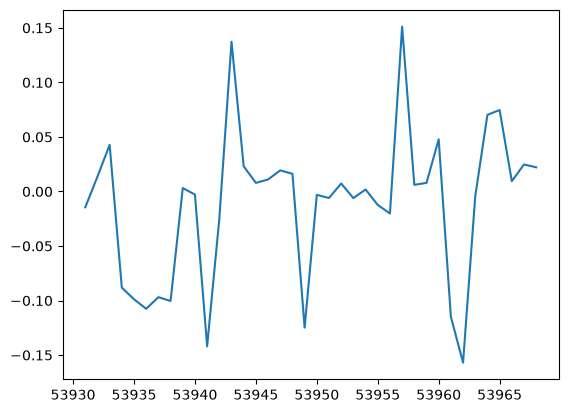

636018491 2025-01-22


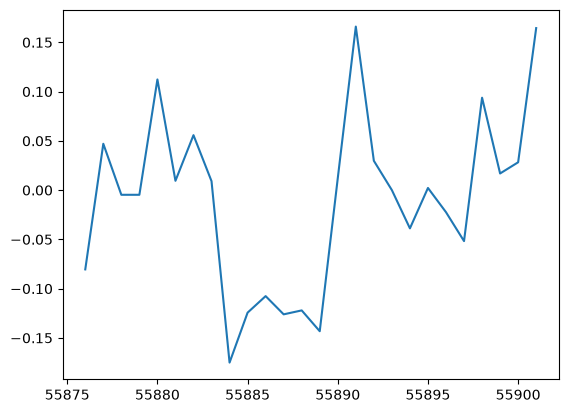

636019341 2025-01-24


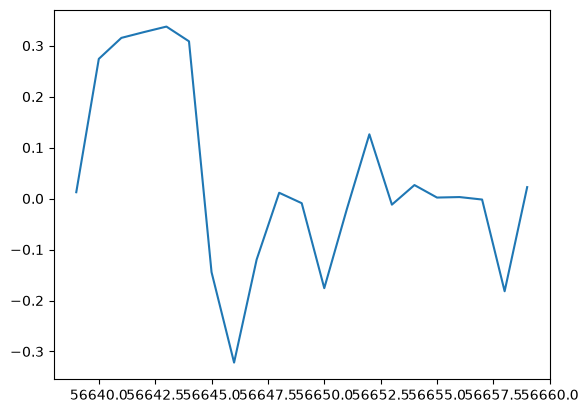

636023127 2025-01-15


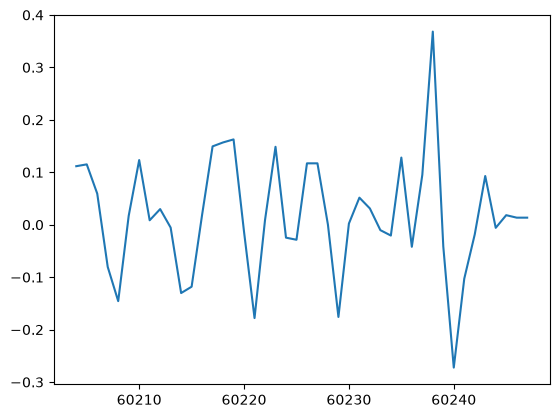

In [31]:
mmsis = anomalies['mmsi'].tolist()
days = anomalies['day'].tolist()

for mmsi, day in zip( mmsis, days ):
    df_raw = df_prepared[
        (df_prepared['MMSI'] == mmsi) &
        (df_prepared['day'] == str(day))
    ]

    print(mmsi, day)
    plt.plot( df_raw['delta_dif'] )
    plt.show()

In [32]:
mask_first_anom = (
    ((test_mmsis) == mmsis[0]) &
    ((test_days) == days[0])
)

mask_second_anom = (
    ((test_mmsis) == mmsis[1]) &
    ((test_days) == days[1])
)

relevant_anom_mask = mask_first_anom | mask_second_anom

In [33]:
df_prepared

,LATITUDE,LONGITUDE,SPEED,COURSE,day,currentSpeed,gust,swellHeight,waveHeight,windSpeed,...,COURSE_vec_y,currentDirection_vec_x,currentDirection_vec_y,swellDirection_vec_x,swellDirection_vec_y,waveDirection_vec_x,waveDirection_vec_y,windDirection_vec_x,windDirection_vec_y,MMSI
0,57.88808,20.27782,15.3,25.4,2025-01-02,0.10,11.30,0.81,1.96,10.59,...,0.264089,0.968433,-0.249273,0.881532,0.472125,0.952422,-0.304782,-0.132291,0.991211,209276000
1,57.91922,20.30604,15.3,25.4,2025-01-02,0.10,11.30,0.81,1.96,10.59,...,0.264089,0.968433,-0.249273,0.881532,0.472125,0.952422,-0.304782,-0.132291,0.991211,209276000
2,57.95271,20.33622,15.3,26.2,2025-01-02,0.10,11.30,0.81,1.96,10.59,...,0.875881,0.968433,-0.249273,0.881532,0.472125,0.952422,-0.304782,-0.132291,0.991211,209276000
3,57.99979,20.37852,15.5,24.8,2025-01-02,0.10,11.30,0.81,1.96,10.59,...,-0.326635,0.968433,-0.249273,0.881532,0.472125,0.952422,-0.304782,-0.132291,0.991211,209276000
4,58.04163,20.42345,15.4,32.2,2025-01-02,0.11,11.93,0.73,1.98,11.56,...,0.706169,0.999690,0.024882,0.886209,0.463286,-0.673485,-0.739201,0.225368,0.974274,209276000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61008,57.18824,19.54813,13.4,209.4,2025-01-06,0.04,14.87,0.48,2.53,13.52,...,0.885100,-0.999952,0.009816,-0.468815,-0.883297,0.215105,0.976591,0.847214,-0.531251,667002345
61009,57.11246,19.47047,13.6,208.8,2025-01-06,0.04,14.87,0.48,2.53,13.52,...,0.993290,-0.999952,0.009816,-0.468815,-0.883297,0.215105,0.976591,0.847214,-0.531251,667002345
61010,57.05979,19.41558,13.4,207.9,2025-01-06,0.04,14.87,0.48,2.53,13.52,...,0.526845,-0.999952,0.009816,-0.468815,-0.883297,0.215105,0.976591,0.847214,-0.531251,667002345
61011,57.04192,19.39704,13.6,209.8,2025-01-06,0.04,14.87,0.48,2.53,13.52,...,0.633995,-0.999952,0.009816,-0.468815,-0.883297,0.215105,0.976591,0.847214,-0.531251,667002345


636018490 2025-01-15


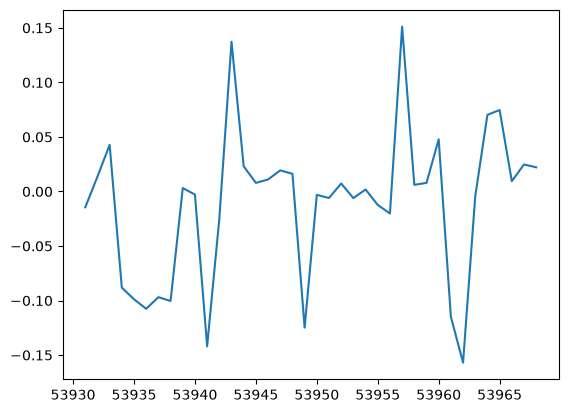

636018491 2025-01-22


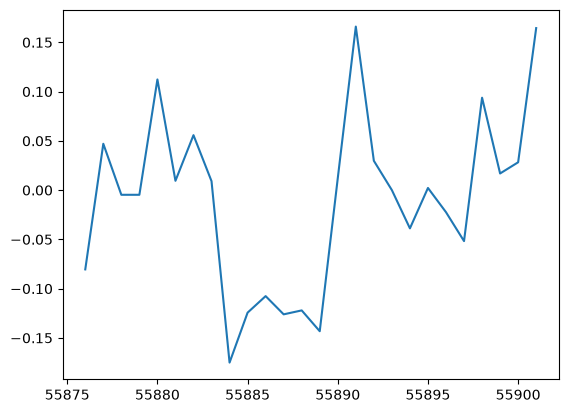

636019341 2025-01-24


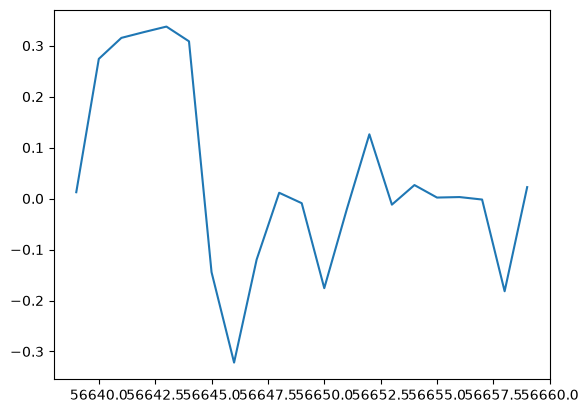

636023127 2025-01-15


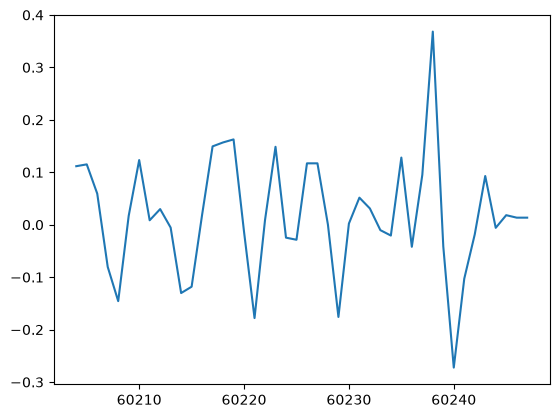

In [34]:
mmsis = anomalies['mmsi'].tolist()
days = anomalies['day'].tolist()

speeds_anomaly = []

for mmsi, day in zip( mmsis, days ):
    df_raw = df_prepared[
        (df_prepared['MMSI'] == mmsi) &
        (df_prepared['day'] == str(day))
    ]

    

    print(mmsi, day)
    plt.plot( df_raw['delta_dif'] )
    plt.show()

In [35]:
col = 'SPEED'
col_anomaly = []

for mmsi, day in zip( mmsis, days ):
    df_raw = df_prepared[
        (df_prepared['MMSI'] == mmsi) &
        (df_prepared['day'] == str(day))
    ]

    col_anomaly.extend(df_raw['SPEED'].tolist())

col_non_anomaly = df_prepared[~df_prepared['MMSI'].isin(mmsis)]['SPEED'].tolist()

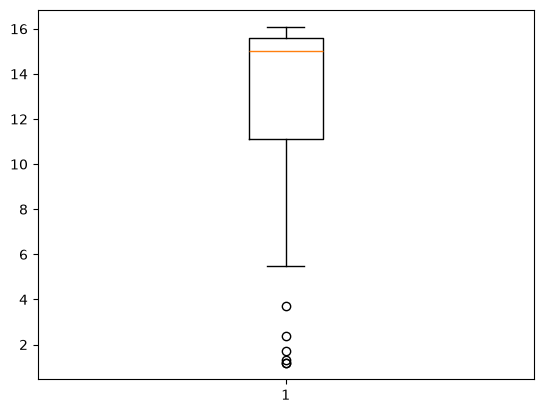

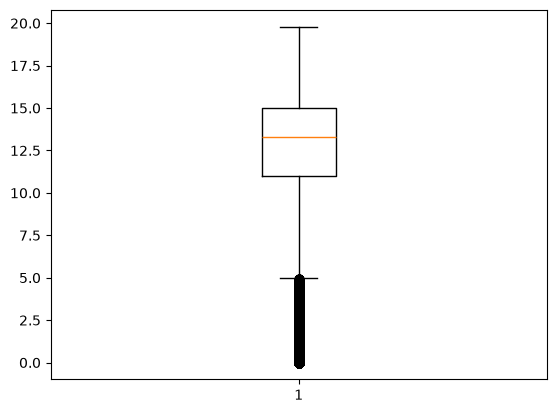

In [36]:
plt.boxplot(col_anomaly)
plt.show()
plt.boxplot(col_non_anomaly)
plt.show()

In [37]:
df_prepared.columns

Index(['LATITUDE', 'LONGITUDE', 'SPEED', 'COURSE', 'day', 'currentSpeed',
       'gust', 'swellHeight', 'waveHeight', 'windSpeed', 'dif', 'COURSE-dif',
       'delta_dif', 'COURSE_vec_x', 'COURSE_vec_y', 'currentDirection_vec_x',
       'currentDirection_vec_y', 'swellDirection_vec_x',
       'swellDirection_vec_y', 'waveDirection_vec_x', 'waveDirection_vec_y',
       'windDirection_vec_x', 'windDirection_vec_y', 'MMSI'],
      dtype='object')

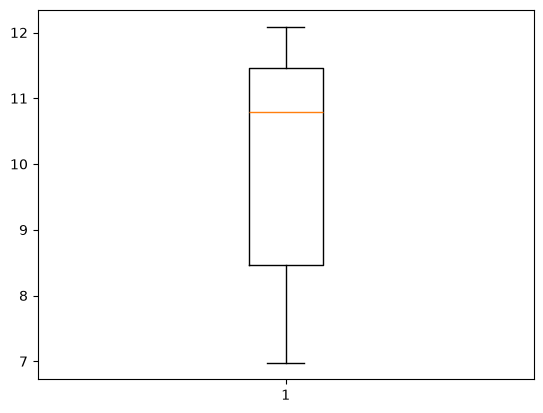

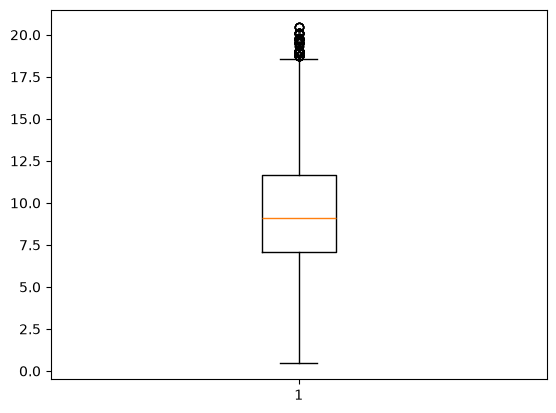

In [38]:
col = 'windSpeed'
col_anomaly = []

for mmsi, day in zip( mmsis, days ):
    df_raw = df_prepared[
        (df_prepared['MMSI'] == mmsi) &
        (df_prepared['day'] == str(day))
    ]

    col_anomaly.extend(df_raw[col].tolist())

col_non_anomaly = df_prepared[~df_prepared['MMSI'].isin(mmsis)][col].tolist()

plt.boxplot(col_anomaly)
plt.show()
plt.boxplot(col_non_anomaly)
plt.show()

In [39]:
import folium

In [40]:
mmsis = anomalies['mmsi'].tolist()
days = anomalies['day'].tolist()

maps = []
for mmsi, day in zip( mmsis, days ):
    m = folium.Map(location=[58.75, 22], zoom_start=6)

    df_raw = df_prepared[
        (df_prepared['MMSI'] == mmsi) &
        (df_prepared['day'] == str(day))
    ]

    coord_list = df_raw.apply(
        lambda row: [ row['LATITUDE'], row['LONGITUDE'] ],
        axis='columns'
    )\
        .tolist()

    folium.PolyLine(
        coord_list,
        opacity=1,
        weight=5
    ).add_to(m)

    maps.append(m)

In [41]:

maps[3]

In [42]:
maps[2]

In [43]:
maps[1]

In [44]:
maps[0]

In [45]:
feature_names = [
    'SPEED', 'COURSE', 'currentSpeed', 'gust', 'swellHeight',
    'waveHeight', 'windSpeed', 'dif', 'COURSE-dif', 'delta_dif',
    'COURSE_vec_x', 'COURSE_vec_y', 'currentDirection_vec_x',
    'currentDirection_vec_y', 'swellDirection_vec_x',
    'swellDirection_vec_y', 'waveDirection_vec_x', 'waveDirection_vec_y',
    'windDirection_vec_x', 'windDirection_vec_y'
]

feature_names = [
    f'{col}_t-{t}'
    for t in range(0,25,5)
    for col in feature_names
]

/tmp/ipykernel_2705/3221758915.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


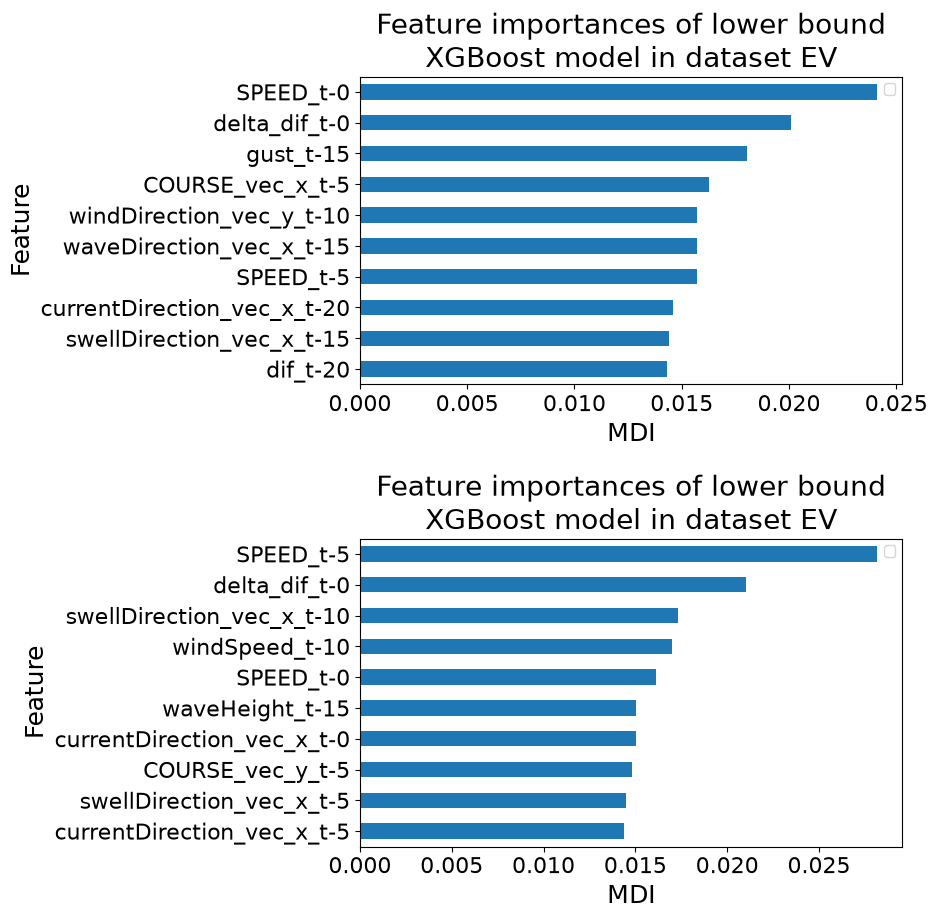

In [46]:
fig, axs = plt.subplots(nrows=2, gridspec_kw={'hspace': 0.5}, figsize=(7,10))

df_low = pd.DataFrame({
    'feat_imp': model_low.feature_importances_,
    'name': feature_names
})

df_low.sort_values('feat_imp').tail(10).plot.barh(x='name', ax=axs[0])

axs[0].set_ylabel('Feature', size=18)
axs[0].set_xlabel('MDI', size=18)
axs[0].legend([])
axs[0].set_title('Feature importances of lower bound\nXGBoost model in dataset EV', size=20)
axs[0].tick_params(axis='both', labelsize=16)

df_high = pd.DataFrame({
    'feat_imp': model_high.feature_importances_,
    'name': feature_names
})

df_high.sort_values('feat_imp').tail(10).plot.barh(x='name', ax=axs[1])

axs[1].set_ylabel('Feature', size=18)
axs[1].set_xlabel('MDI', size=18)
axs[1].legend([])
axs[1].set_title('Feature importances of lower bound\nXGBoost model in dataset EV', size=20)
axs[1].tick_params(axis='both', labelsize=16)

plt.tight_layout()
# https://stackoverflow.com/questions/35393863/matplotlib-error-figure-includes-axes-that-are-not-compatible-with-tight-layou#comment139970201_39089653
plt.savefig('mdi-values-eagles.png', dpi=750,bbox_inches='tight')
plt.show()

In [47]:
explainer_high = shap.TreeExplainer(model_high)
explainer_low = shap.TreeExplainer(model_low)

In [48]:
[f for f in feature_names if 't-0' in f]

['SPEED_t-0',
 'COURSE_t-0',
 'currentSpeed_t-0',
 'gust_t-0',
 'swellHeight_t-0',
 'waveHeight_t-0',
 'windSpeed_t-0',
 'dif_t-0',
 'COURSE-dif_t-0',
 'delta_dif_t-0',
 'COURSE_vec_x_t-0',
 'COURSE_vec_y_t-0',
 'currentDirection_vec_x_t-0',
 'currentDirection_vec_y_t-0',
 'swellDirection_vec_x_t-0',
 'swellDirection_vec_y_t-0',
 'waveDirection_vec_x_t-0',
 'waveDirection_vec_y_t-0',
 'windDirection_vec_x_t-0',
 'windDirection_vec_y_t-0']

# Code is from `from https://github.com/amaa11/NMR`

In [49]:
# from https://github.com/amaa11/NMR
X_train_df = pd.DataFrame(X_train, columns=feature_names)
X_test_df = pd.DataFrame(eagles_x, columns=feature_names)
y_train_dif = y_train[:, 2]

dicts = dict()
m = 0
MPM_list = []

while X_train_df.shape[1] != 1:

    MPM = 0
    NF = X_train_df.shape[1]
    for j in range(1, NF, 2):
        summ = NF-j
        MPM = MPM+summ
    MPM = MPM*2
    MPM_list.append(MPM)
    #print('MPM :', MPM)
    
    ITER_NUMBER = X_train_df.shape[1]                          ## number of features in each iteration
    model_low = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=0.025,
        device='gpu',
        **best_hyper
    )
    model_low.fit(X_train_df, y_train_dif)                      ## fit the data to the model
    ypred_test = model_low.predict(X_test_df)                             ## predict test data
    
    # fit shap
    explainer = shap.TreeExplainer(model_low)

    # apply shap to test data
    shap_values = explainer.shap_values(X_test_df)
    
    # the follwoing steps to represents the SHAP outcome (informative predictors) as datafram
    vals= np.abs(shap_values).mean(0)
    feature_importance = pd.DataFrame(list(zip(X_train_df.columns,vals)),columns=['Features','feature_importance_vals'])
    feature_importance.sort_values(by=['feature_importance_vals'],ascending=False,inplace=True)
    feature_importance.reset_index(inplace=True, drop=True)
    feature_importance.index = np.arange(1, len(feature_importance) + 1)
    #print(feature_importance)
    FEATURES = feature_importance[['Features']]
    #print(FEATURES)
    for i in range(FEATURES.shape[0]):
        #print(FEATURES.iloc[i]['Features'], end = " ")
        #print(FEATURES.iloc[i].name, end = " ")
        #for key in dicts:
        if FEATURES.iloc[i]['Features'] in dicts:
            dicts[FEATURES.iloc[i]['Features']].append(FEATURES.iloc[i].name + m)
        else:
            dicts[FEATURES.iloc[i]['Features']] = [FEATURES.iloc[i].name + m]
    
    m = m+1
    # identify the most informative predictor
    Top_feature = feature_importance.iloc[0]['Features']
    print('Iteration:', ITER_NUMBER, '\tTop feature:', Top_feature)
    
    # remove the most informative predictor from train and test data
    X_train_df.drop([Top_feature], axis=1, inplace=True)
    X_train_df.reset_index(inplace=True, drop=True)
    X_test_df.drop([Top_feature], axis=1, inplace=True)
    X_test_df.reset_index(inplace=True, drop=True)

MPM_list.pop(0)

Iteration: 100 	Top feature: dif_t-0
Iteration: 99 	Top feature: dif_t-5
Iteration: 98 	Top feature: SPEED_t-0
Iteration: 97 	Top feature: SPEED_t-5
Iteration: 96 	Top feature: SPEED_t-10
Iteration: 95 	Top feature: dif_t-10
Iteration: 94 	Top feature: dif_t-15
Iteration: 93 	Top feature: SPEED_t-15
Iteration: 92 	Top feature: SPEED_t-20
Iteration: 91 	Top feature: dif_t-20
Iteration: 90 	Top feature: delta_dif_t-0
Iteration: 89 	Top feature: delta_dif_t-5
Iteration: 88 	Top feature: delta_dif_t-10
Iteration: 87 	Top feature: delta_dif_t-20
Iteration: 86 	Top feature: waveHeight_t-20
Iteration: 85 	Top feature: waveHeight_t-15
Iteration: 84 	Top feature: waveHeight_t-10
Iteration: 83 	Top feature: waveHeight_t-5
Iteration: 82 	Top feature: waveHeight_t-0
Iteration: 81 	Top feature: delta_dif_t-15
Iteration: 80 	Top feature: COURSE-dif_t-0
Iteration: 79 	Top feature: COURSE-dif_t-10
Iteration: 78 	Top feature: COURSE-dif_t-5
Iteration: 77 	Top feature: COURSE_t-5
Iteration: 76 	Top feat

5000

In [50]:
lenOfLists=len(dicts)
#function to add item at index=len ... append item
def add_item_to_dict(my_dict, key, value):
    my_dict[len(my_dict)] = [key,value]

    
sorted_dict = {}

for index in range(1,lenOfLists):
    for key, value in dicts.items():
        if len(value)==index:
            add_item_to_dict(sorted_dict,key,value)

#calculate sum of changes
sumOfChanges={}
#first is zero
add_item_to_dict(sumOfChanges,sorted_dict[0][0],0)

for index in range(1,lenOfLists-1):  
    key=sorted_dict[index][0]
    soc=0
    for t in range(index,lenOfLists):        
        soc+=abs(sorted_dict[t][1][index]-sorted_dict[t][1][index-1])
        #print(sorted_dict[t][1][index],sorted_dict[t][1][index-1],(sorted_dict[t][1][index]-sorted_dict[t][1][index-1]))
    add_item_to_dict(sumOfChanges,key,soc)
    #print(soc,'----') 
#last is same to last -1
add_item_to_dict(sumOfChanges,sorted_dict[lenOfLists-1][0],sumOfChanges[lenOfLists-2][1])
#print(sorted_dict)
#print(sumOfChanges)
sumOfChanges.popitem()
first_key = next(iter(sumOfChanges))
del sumOfChanges[first_key]
rates = []
ite=0
for key, value in sumOfChanges.items():    
    rates.append(value[1]/MPM_list[ite])
    ite=ite+1
#print(rates)
print("NMR value : ", round(np.mean(rates), 3))

NMR value :  0.32


In [51]:
# from https://github.com/amaa11/NMR
X_train_df = pd.DataFrame(X_train, columns=feature_names)
X_test_df = pd.DataFrame(eagles_x, columns=feature_names)
y_train_dif = y_train[:, 2]

dicts = dict()
m = 0
MPM_list = []

while X_train_df.shape[1] != 1:

    MPM = 0
    NF = X_train_df.shape[1]
    for j in range(1, NF, 2):
        summ = NF-j
        MPM = MPM+summ
    MPM = MPM*2
    MPM_list.append(MPM)
    #print('MPM :', MPM)
    
    ITER_NUMBER = X_train_df.shape[1]                          ## number of features in each iteration
    model_high = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=0.975,
        device='gpu',
        **best_hyper
    )
    model_high.fit(X_train_df, y_train_dif)                      ## fit the data to the model
    ypred_test = model_high.predict (X_test_df)                             ## predict test data
    
    # fit shap
    explainer = shap.TreeExplainer(model_high)

    # apply shap to test data
    shap_values = explainer.shap_values(X_test_df)
    
    # the follwoing steps to represents the SHAP outcome (informative predictors) as datafram
    vals= np.abs(shap_values).mean(0)
    feature_importance = pd.DataFrame(list(zip(X_train_df.columns,vals)),columns=['Features','feature_importance_vals'])
    feature_importance.sort_values(by=['feature_importance_vals'],ascending=False,inplace=True)
    feature_importance.reset_index(inplace=True, drop=True)
    feature_importance.index = np.arange(1, len(feature_importance) + 1)
    #print(feature_importance)
    FEATURES = feature_importance[['Features']]
    #print(FEATURES)
    for i in range(FEATURES.shape[0]):
        #print(FEATURES.iloc[i]['Features'], end = " ")
        #print(FEATURES.iloc[i].name, end = " ")
        #for key in dicts:
        if FEATURES.iloc[i]['Features'] in dicts:
            dicts[FEATURES.iloc[i]['Features']].append(FEATURES.iloc[i].name + m)
        else:
            dicts[FEATURES.iloc[i]['Features']] = [FEATURES.iloc[i].name + m]
    
    m = m+1
    # identify the most informative predictor
    Top_feature = feature_importance.iloc[0]['Features']
    print('Iteration:', ITER_NUMBER, '\tTop feature:', Top_feature)
    
    # remove the most informative predictor from train and test data
    X_train_df.drop([Top_feature], axis=1, inplace=True)
    X_train_df.reset_index(inplace=True, drop=True)
    X_test_df.drop([Top_feature], axis=1, inplace=True)
    X_test_df.reset_index(inplace=True, drop=True)

MPM_list.pop(0)

Iteration: 100 	Top feature: delta_dif_t-0
Iteration: 99 	Top feature: SPEED_t-0
Iteration: 98 	Top feature: SPEED_t-5
Iteration: 97 	Top feature: SPEED_t-10
Iteration: 96 	Top feature: SPEED_t-15
Iteration: 95 	Top feature: SPEED_t-20
Iteration: 94 	Top feature: dif_t-0
Iteration: 93 	Top feature: dif_t-5
Iteration: 92 	Top feature: dif_t-10
Iteration: 91 	Top feature: dif_t-15
Iteration: 90 	Top feature: dif_t-20
Iteration: 89 	Top feature: delta_dif_t-5
Iteration: 88 	Top feature: delta_dif_t-10
Iteration: 87 	Top feature: delta_dif_t-15
Iteration: 86 	Top feature: delta_dif_t-20
Iteration: 85 	Top feature: COURSE-dif_t-0
Iteration: 84 	Top feature: waveHeight_t-20
Iteration: 83 	Top feature: waveHeight_t-15
Iteration: 82 	Top feature: waveHeight_t-10
Iteration: 81 	Top feature: waveHeight_t-0
Iteration: 80 	Top feature: waveHeight_t-5
Iteration: 79 	Top feature: COURSE-dif_t-10
Iteration: 78 	Top feature: COURSE-dif_t-5
Iteration: 77 	Top feature: COURSE-dif_t-15
Iteration: 76 	Top

5000

In [52]:
lenOfLists=len(dicts)
#function to add item at index=len ... append item
def add_item_to_dict(my_dict, key, value):
    my_dict[len(my_dict)] = [key,value]

    
sorted_dict = {}

for index in range(1,lenOfLists):
    for key, value in dicts.items():
        if len(value)==index:
            add_item_to_dict(sorted_dict,key,value)

#calculate sum of changes
sumOfChanges={}
#first is zero
add_item_to_dict(sumOfChanges,sorted_dict[0][0],0)

for index in range(1,lenOfLists-1):  
    key=sorted_dict[index][0]
    soc=0
    for t in range(index,lenOfLists):        
        soc+=abs(sorted_dict[t][1][index]-sorted_dict[t][1][index-1])
        #print(sorted_dict[t][1][index],sorted_dict[t][1][index-1],(sorted_dict[t][1][index]-sorted_dict[t][1][index-1]))
    add_item_to_dict(sumOfChanges,key,soc)
    #print(soc,'----') 
#last is same to last -1
add_item_to_dict(sumOfChanges,sorted_dict[lenOfLists-1][0],sumOfChanges[lenOfLists-2][1])
#print(sorted_dict)
#print(sumOfChanges)
sumOfChanges.popitem()
first_key = next(iter(sumOfChanges))
del sumOfChanges[first_key]
rates = []
ite=0
for key, value in sumOfChanges.items():    
    rates.append(value[1]/MPM_list[ite])
    ite=ite+1
#print(rates)
print("NMR value : ", round(np.mean(rates), 3))

NMR value :  0.327


In [53]:
# from https://github.com/amaa11/NMR
X_train_df = pd.DataFrame(X_train, columns=feature_names)
X_test_df = pd.DataFrame(vezhen_x, columns=feature_names)
y_train_dif = y_train[:, 2]

dicts = dict()
m = 0
MPM_list = []

while X_train_df.shape[1] != 1:

    MPM = 0
    NF = X_train_df.shape[1]
    for j in range(1, NF, 2):
        summ = NF-j
        MPM = MPM+summ
    MPM = MPM*2
    MPM_list.append(MPM)
    #print('MPM :', MPM)
    
    ITER_NUMBER = X_train_df.shape[1]                          ## number of features in each iteration
    model_high = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=0.025,
        device='gpu',
        **best_hyper
    )
    model_high.fit(X_train_df, y_train_dif)                      ## fit the data to the model
    ypred_test = model_high.predict (X_test_df)                             ## predict test data
    
    # fit shap
    explainer = shap.TreeExplainer(model_high)

    # apply shap to test data
    shap_values = explainer.shap_values(X_test_df)
    
    # the follwoing steps to represents the SHAP outcome (informative predictors) as datafram
    vals= np.abs(shap_values).mean(0)
    feature_importance = pd.DataFrame(list(zip(X_train_df.columns,vals)),columns=['Features','feature_importance_vals'])
    feature_importance.sort_values(by=['feature_importance_vals'],ascending=False,inplace=True)
    feature_importance.reset_index(inplace=True, drop=True)
    feature_importance.index = np.arange(1, len(feature_importance) + 1)
    #print(feature_importance)
    FEATURES = feature_importance[['Features']]
    #print(FEATURES)
    for i in range(FEATURES.shape[0]):
        #print(FEATURES.iloc[i]['Features'], end = " ")
        #print(FEATURES.iloc[i].name, end = " ")
        #for key in dicts:
        if FEATURES.iloc[i]['Features'] in dicts:
            dicts[FEATURES.iloc[i]['Features']].append(FEATURES.iloc[i].name + m)
        else:
            dicts[FEATURES.iloc[i]['Features']] = [FEATURES.iloc[i].name + m]
    
    m = m+1
    # identify the most informative predictor
    Top_feature = feature_importance.iloc[0]['Features']
    print('Iteration:', ITER_NUMBER, '\tTop feature:', Top_feature)
    
    # remove the most informative predictor from train and test data
    X_train_df.drop([Top_feature], axis=1, inplace=True)
    X_train_df.reset_index(inplace=True, drop=True)
    X_test_df.drop([Top_feature], axis=1, inplace=True)
    X_test_df.reset_index(inplace=True, drop=True)

MPM_list.pop(0)
lenOfLists=len(dicts)
#function to add item at index=len ... append item
def add_item_to_dict(my_dict, key, value):
    my_dict[len(my_dict)] = [key,value]

    
sorted_dict = {}

for index in range(1,lenOfLists):
    for key, value in dicts.items():
        if len(value)==index:
            add_item_to_dict(sorted_dict,key,value)

#calculate sum of changes
sumOfChanges={}
#first is zero
add_item_to_dict(sumOfChanges,sorted_dict[0][0],0)

for index in range(1,lenOfLists-1):  
    key=sorted_dict[index][0]
    soc=0
    for t in range(index,lenOfLists):        
        soc+=abs(sorted_dict[t][1][index]-sorted_dict[t][1][index-1])
        #print(sorted_dict[t][1][index],sorted_dict[t][1][index-1],(sorted_dict[t][1][index]-sorted_dict[t][1][index-1]))
    add_item_to_dict(sumOfChanges,key,soc)
    #print(soc,'----') 
#last is same to last -1
add_item_to_dict(sumOfChanges,sorted_dict[lenOfLists-1][0],sumOfChanges[lenOfLists-2][1])
#print(sorted_dict)
#print(sumOfChanges)
sumOfChanges.popitem()
first_key = next(iter(sumOfChanges))
del sumOfChanges[first_key]
rates = []
ite=0
for key, value in sumOfChanges.items():    
    rates.append(value[1]/MPM_list[ite])
    ite=ite+1
#print(rates)
print("NMR value : ", round(np.mean(rates), 3))

Iteration: 100 	Top feature: dif_t-0
Iteration: 99 	Top feature: dif_t-5
Iteration: 98 	Top feature: dif_t-10
Iteration: 97 	Top feature: SPEED_t-0
Iteration: 96 	Top feature: dif_t-15
Iteration: 95 	Top feature: SPEED_t-5
Iteration: 94 	Top feature: SPEED_t-10
Iteration: 93 	Top feature: dif_t-20
Iteration: 92 	Top feature: SPEED_t-15
Iteration: 91 	Top feature: SPEED_t-20
Iteration: 90 	Top feature: delta_dif_t-0
Iteration: 89 	Top feature: delta_dif_t-5
Iteration: 88 	Top feature: delta_dif_t-10
Iteration: 87 	Top feature: delta_dif_t-15
Iteration: 86 	Top feature: delta_dif_t-20
Iteration: 85 	Top feature: waveHeight_t-20
Iteration: 84 	Top feature: waveHeight_t-15
Iteration: 83 	Top feature: waveHeight_t-10
Iteration: 82 	Top feature: waveHeight_t-5
Iteration: 81 	Top feature: waveHeight_t-0
Iteration: 80 	Top feature: COURSE-dif_t-0
Iteration: 79 	Top feature: windSpeed_t-0
Iteration: 78 	Top feature: windSpeed_t-5
Iteration: 77 	Top feature: gust_t-0
Iteration: 76 	Top feature: 

In [54]:
# from https://github.com/amaa11/NMR
X_train_df = pd.DataFrame(X_train, columns=feature_names)
X_test_df = pd.DataFrame(vezhen_x, columns=feature_names)
y_train_dif = y_train[:, 2]

dicts = dict()
m = 0
MPM_list = []

while X_train_df.shape[1] != 1:

    MPM = 0
    NF = X_train_df.shape[1]
    for j in range(1, NF, 2):
        summ = NF-j
        MPM = MPM+summ
    MPM = MPM*2
    MPM_list.append(MPM)
    #print('MPM :', MPM)
    
    ITER_NUMBER = X_train_df.shape[1]                          ## number of features in each iteration
    model_high = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=0.975,
        device='gpu',
        **best_hyper
    )
    model_high.fit(X_train_df, y_train_dif)                      ## fit the data to the model
    ypred_test = model_high.predict (X_test_df)                             ## predict test data
    
    # fit shap
    explainer = shap.TreeExplainer(model_high)

    # apply shap to test data
    shap_values = explainer.shap_values(X_test_df)
    
    # the follwoing steps to represents the SHAP outcome (informative predictors) as datafram
    vals= np.abs(shap_values).mean(0)
    feature_importance = pd.DataFrame(list(zip(X_train_df.columns,vals)),columns=['Features','feature_importance_vals'])
    feature_importance.sort_values(by=['feature_importance_vals'],ascending=False,inplace=True)
    feature_importance.reset_index(inplace=True, drop=True)
    feature_importance.index = np.arange(1, len(feature_importance) + 1)
    #print(feature_importance)
    FEATURES = feature_importance[['Features']]
    #print(FEATURES)
    for i in range(FEATURES.shape[0]):
        #print(FEATURES.iloc[i]['Features'], end = " ")
        #print(FEATURES.iloc[i].name, end = " ")
        #for key in dicts:
        if FEATURES.iloc[i]['Features'] in dicts:
            dicts[FEATURES.iloc[i]['Features']].append(FEATURES.iloc[i].name + m)
        else:
            dicts[FEATURES.iloc[i]['Features']] = [FEATURES.iloc[i].name + m]
    
    m = m+1
    # identify the most informative predictor
    Top_feature = feature_importance.iloc[0]['Features']
    print('Iteration:', ITER_NUMBER, '\tTop feature:', Top_feature)
    
    # remove the most informative predictor from train and test data
    X_train_df.drop([Top_feature], axis=1, inplace=True)
    X_train_df.reset_index(inplace=True, drop=True)
    X_test_df.drop([Top_feature], axis=1, inplace=True)
    X_test_df.reset_index(inplace=True, drop=True)

MPM_list.pop(0)
lenOfLists=len(dicts)
#function to add item at index=len ... append item
def add_item_to_dict(my_dict, key, value):
    my_dict[len(my_dict)] = [key,value]

    
sorted_dict = {}

for index in range(1,lenOfLists):
    for key, value in dicts.items():
        if len(value)==index:
            add_item_to_dict(sorted_dict,key,value)

#calculate sum of changes
sumOfChanges={}
#first is zero
add_item_to_dict(sumOfChanges,sorted_dict[0][0],0)

for index in range(1,lenOfLists-1):  
    key=sorted_dict[index][0]
    soc=0
    for t in range(index,lenOfLists):        
        soc+=abs(sorted_dict[t][1][index]-sorted_dict[t][1][index-1])
        #print(sorted_dict[t][1][index],sorted_dict[t][1][index-1],(sorted_dict[t][1][index]-sorted_dict[t][1][index-1]))
    add_item_to_dict(sumOfChanges,key,soc)
    #print(soc,'----') 
#last is same to last -1
add_item_to_dict(sumOfChanges,sorted_dict[lenOfLists-1][0],sumOfChanges[lenOfLists-2][1])
#print(sorted_dict)
#print(sumOfChanges)
sumOfChanges.popitem()
first_key = next(iter(sumOfChanges))
del sumOfChanges[first_key]
rates = []
ite=0
for key, value in sumOfChanges.items():    
    rates.append(value[1]/MPM_list[ite])
    ite=ite+1
#print(rates)
print("NMR value : ", round(np.mean(rates), 3))

Iteration: 100 	Top feature: dif_t-0
Iteration: 99 	Top feature: dif_t-5
Iteration: 98 	Top feature: dif_t-10
Iteration: 97 	Top feature: dif_t-15
Iteration: 96 	Top feature: dif_t-20
Iteration: 95 	Top feature: SPEED_t-0
Iteration: 94 	Top feature: SPEED_t-5
Iteration: 93 	Top feature: SPEED_t-10
Iteration: 92 	Top feature: SPEED_t-15
Iteration: 91 	Top feature: SPEED_t-20
Iteration: 90 	Top feature: delta_dif_t-0
Iteration: 89 	Top feature: delta_dif_t-5
Iteration: 88 	Top feature: delta_dif_t-10
Iteration: 87 	Top feature: delta_dif_t-15
Iteration: 86 	Top feature: delta_dif_t-20
Iteration: 85 	Top feature: gust_t-0
Iteration: 84 	Top feature: gust_t-20
Iteration: 83 	Top feature: gust_t-5
Iteration: 82 	Top feature: gust_t-15
Iteration: 81 	Top feature: gust_t-10
Iteration: 80 	Top feature: windSpeed_t-0
Iteration: 79 	Top feature: windSpeed_t-5
Iteration: 78 	Top feature: windSpeed_t-10
Iteration: 77 	Top feature: windSpeed_t-15
Iteration: 76 	Top feature: windSpeed_t-20
Iteration